<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="../592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">NC County Labelling Practice</div>
    </div>
</div>



Homework: Code each of the county names attached to the centroid. \
Or like the population of the county. 
https://ncqsoparty.org/wp-content/uploads/2021/05/Mults-and-States-UPDATED-5_13_2021-PDF.pdf

In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt

In [11]:
# Getting the census boundary data.
url = "https://www2.census.gov/geo/tiger/GENZ2024/shp/cb_2024_us_county_500k.zip" 
counties = gpd.read_file(url)
nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()
ncc = nc_counties.to_crs(epsg=6543)

In [74]:
# Creating a plotting function.  
def nc_plot(ax, stroke, fill):
    ncc.plot(ax=ax, edgecolor=stroke, facecolor=fill)

Text(2104249.3454925506, 187867.29290058636, 'COL')

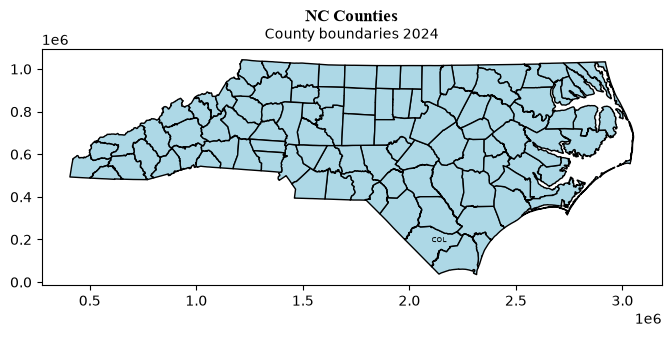

In [75]:
# Plotting example. 
fig, ax = plt.subplots(figsize=(8, 4))
nc_plot(ax, "black", "lightblue")
ax.set_title("NC Counties", fontsize=12, fontweight="bold", fontname="Times New Roman", pad=20)
ax.text(0.5, 1.03, 
        "County boundaries 2024", 
        # Uses the coordinate system of the figure. 
        # Even though ncc is in the local projection, 
        # the computer stores the coordinates using a different system (a proportion). 
        transform=ax.transAxes, 
        ha='center', 
        va='bottom', 
        fontsize='10')

ax.text(2104249.3454925506, 187867.29290058636, 
        "COL", 
        fontsize=5)

An example for how to create text: 
```python
ax.text(0.5, 1.06, 
        "County boundaries 2024", 
        transform=ax.transAxes,
        fontsize='10')
```
I need to iterate through each row, extract the x and y coordinates for the first two arguments and the county name for the third argument. For the county name, subset just the first three letters and capitalize it. 

In [16]:
# Subsetting and capitalizing a string. 
string = "string"
string[0:3].upper()

'STR'

In [31]:
ncc['centroids'] = ncc.geometry.centroid

Text(0.05, 0.1, 'Author: Abigail Kim\nSource: 2024 Census')

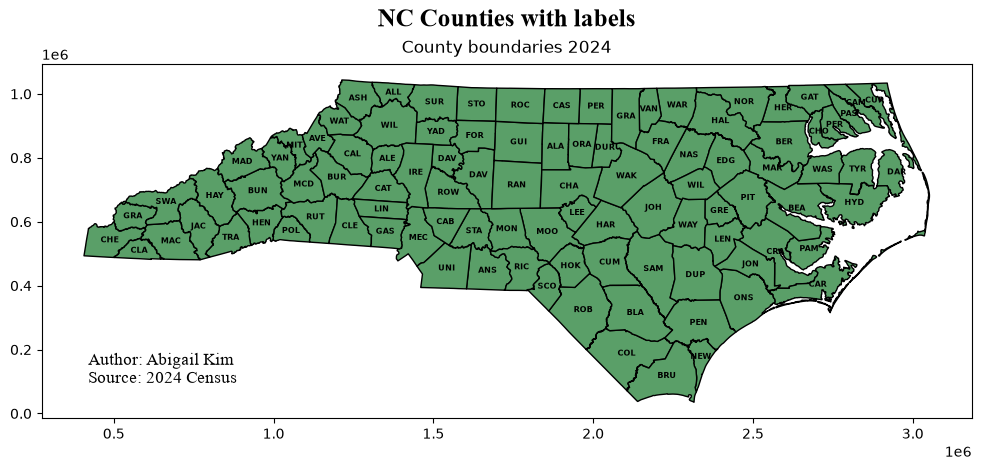

In [118]:
fig, ax = plt.subplots(figsize=(12, 6))
nc_plot(ax, "black", "#5A9F68")

for row in range(len(ncc)): 
    county_name = ncc.iloc[row]['NAMELSAD']
    abbreviation = county_name[0:3].upper()
    x = ncc.iloc[row]['centroids'].x
    y = ncc.iloc[row]['centroids'].y

    ax.text(x, y, 
        abbreviation, 
        fontsize='6', 
        fontweight="bold",
        # Uses the center of the text to attach to centroid. 
        ha="center",
        va="center")

# Formatting text 
ax.set_title("NC Counties with labels", fontsize=18, fontweight="bold", fontname="Times New Roman", pad=27)
ax.text(0.5, 1.02, 
        "County boundaries 2024", 
        # Uses the coordinate system of the figure. 
        # Even though ncc is in the local projection, 
        # the computer stores the coordinates using a different system (a proportion). 
        transform=ax.transAxes, 
        ha='center', 
        va='bottom', 
        fontsize=12)

# Credits text. 
ax.text(0.05, 0.1, 
        "Author: Abigail Kim\nSource: 2024 Census",
        fontname="Times New Roman",
        transform=ax.transAxes,
        fontsize=12)

Text(0.05, 0.1, 'Author: Abigail Kim\nSource: 2024 Census')

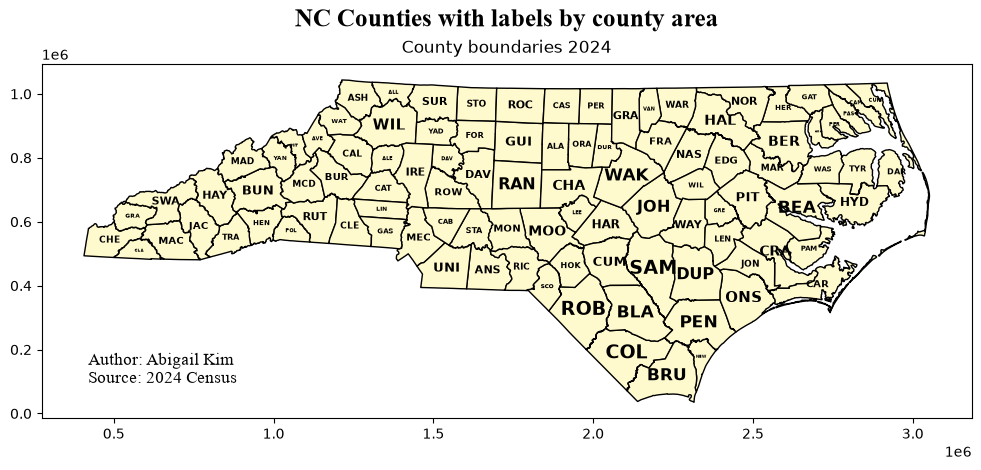

In [119]:
# In class example 
fig, ax = plt.subplots(figsize=(12, 6))
nc_plot(ax, "black", "#fffacd")

for row in range(len(ncc)): 
    county_name = ncc.iloc[row]['NAMELSAD']
    abbreviation = county_name[0:3].upper()
    x = ncc.iloc[row]['centroids'].x
    y = ncc.iloc[row]['centroids'].y

    ax.text(x, y, 
        abbreviation, 
        fontsize=ncc.iloc[row]['ALAND']/180_000_000, 
        fontweight="bold",
        # Uses the center of the text to attach to centroid. 
        ha="center",
        va="center")

# Formatting text 
ax.set_title("NC Counties with labels by county area", fontsize=18, fontweight="bold", fontname="Times New Roman", pad=27)
ax.text(0.5, 1.02, 
        "County boundaries 2024", 
        # Uses the coordinate system of the figure. 
        # Even though ncc is in the local projection, 
        # the computer stores the coordinates using a different system (a proportion). 
        transform=ax.transAxes, 
        ha='center', 
        va='bottom', 
        fontsize=12)

# Credits text
ax.text(0.05, 0.1, 
        "Author: Abigail Kim\nSource: 2024 Census",
        fontname="Times New Roman",
        transform=ax.transAxes,
        fontsize=12)

Normalize with (value - min) / range 